# The final size: solving the relation and comparing it with the simulated course

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- solve $z = 1 - e^{-R_0 z}$ numerically and draw its solution against $R_0$;
- place the baked cases on that curve;
- show that two runs with the same $R_0$ and different time courses end at the same final size.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and prints their versions.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


The engine is imported from `data-pipeline/` by its path, as in topic 01.

In [2]:
# The notebook sits three folders below the repository root; the pipeline's modules are imported by their path
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams
from pipeline.oracles import final_size

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Data

The parameters of the five baked cases.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json`, `data/derived/manifests/<case>.json`.

The next cell defines the readers and lists the cases.

In [3]:
# Two readers of the committed artifacts: a missing file stops the notebook and names its path
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("cases that can take off:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
cases that can take off: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


## Method

The fraction $z$ of the population ever infected solves the final-size relation (Kermack and McKendrick, 1927; Miller, 2012):

$$z = 1 - e^{-R_0 z}$$

It does not contain the contact rate or the recovery rate separately, only their ratio, nor any time: it is independent of the time course. The cell below calls `final_size` of `data-pipeline/pipeline/oracles.py`, an oracle that shares no code with the engine and solves it by fixed-point iteration: starting from $z = 1$, repeat $z \leftarrow 1 - e^{-R_0 z}$ until it stops changing. It prints the first iterations for the epidemic case, to see the convergence.

In [4]:
# Solve the final-size relation by fixed-point iteration, printing the first iterations and their count for R0 = 2.75
first = []
solution = final_size(2.75, trace=first)
print("first iterations:", [round(float(v), 5) for v in first[:6]], "... iterations in all:", len(first))
print("z =", round(solution, 6))

first iterations: [0.93607, 0.92379, 0.92117, 0.9206, 0.92047, 0.92044] ... iterations in all: 18
z = 0.920437


Now the solution for a range of $R_0$, with the four baked cases placed on the curve at their $R_0$ and their simulated attack rate (the share of the population in R at the end of the horizon). The cell also lists the numbers.

EX01_subcritical   R0= 0.72  z=0.0000  simulated=0.0018
EX02_epidemic      R0= 2.75  z=0.9204  simulated=0.9237
EX03_fast_burn     R0= 6.00  z=0.9975  simulated=0.9982
EX04_slow_spread   R0= 1.20  z=0.3137  simulated=0.2993


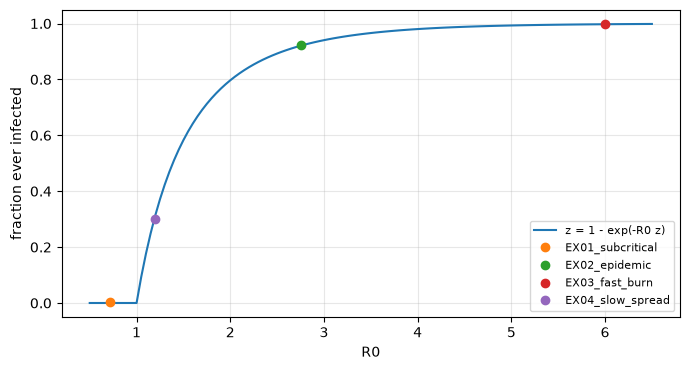

In [5]:
# Draw z against R0 and place each baked case at (R0, simulated attack rate)
grid = np.linspace(0.5, 6.5, 121)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, [final_size(g) for g in grid], label="z = 1 - exp(-R0 z)")
for case_id in OUTBREAKS:
    p = params_of(case_id)
    r = simulate(p)
    r0 = p.beta / p.gamma
    ax.plot([r0], [r.attack_rate], "o", label=case_id)
    print(f"{case_id:18s} R0={r0:5.2f}  z={final_size(r0):.4f}  simulated={r.attack_rate:.4f}")
ax.set_xlabel("R0")
ax.set_ylabel("fraction ever infected")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

The relation says the time course does not matter. To check, this cell runs two cases with the same $R_0 = 2.75$: the epidemic case ($\beta = 0.55$, $\gamma = 0.20$) and one twice as fast ($\beta = 1.10$, $\gamma = 0.40$). The peak should come about twice as early and the final size should be the same.

In [6]:
# Two runs with the same R0 and different speed: the peak moves, the final size does not
base = params_of("EX02_epidemic")
fast = SIRParams("twice_as_fast", base.beta * 2, base.gamma * 2, base.N, base.I0, base.days)
for label, q in (("EX02_epidemic", base), ("twice as fast", fast)):
    r = simulate(q)
    print(f"{label:18s} R0={q.beta / q.gamma:.2f}  peak on day {r.t_peak:6.2f}  attack rate={r.attack_rate:.4f}")

EX02_epidemic      R0=2.75  peak on day  24.25  attack rate=0.9237
twice as fast      R0=2.75  peak on day  12.50  attack rate=0.9269


## Results

The iteration converges in 18 steps (the first values already sit near 0.92) and gives $z \approx 0.9204$ for $R_0 = 2.75$. In the figure, the epidemic and fast-burn cases lie close to the curve, slightly above it: the engine's attack rate is a few thousandths larger, the first-order overshoot of Forward Euler at a quarter-day step (measured in notebook 02 of topic 01). The slow-spread case lies below the curve because its outbreak is still running at the horizon, so the relation, which describes the end of the outbreak, does not apply to it yet. The sub-critical case sits near zero (0.0018, the initial infected people and the few they infect), as the only solution of the relation for $R_0 \le 1$ is zero. In the last table the two speeds end at nearly the same attack rate (0.9237 and 0.9269) while their peaks differ by a factor of about two (day 24.25 and day 12.5): the final size depends on $R_0$ and not on the time course. The small difference between the two attack rates is the Euler error again: the faster course takes the same quarter-day step over a course twice as fast. The remaining difference between the engine and $z$ is not explained here: the next notebook of this topic accounts for it.

## Summary

- The final size solves $z = 1 - e^{-R_0 z}$, by a short fixed-point iteration.
- It depends on $R_0$ only: two runs at different speeds end at the same size.
- It applies to outbreaks that end inside the horizon; the slow-spread case does not.
- Next: notebook 03 compares this with the state of the art and accounts for the remaining difference.

## References

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the cases of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

What each work is credited with is what the research basis of the SDD (`docs/design/SDD.md`) records; the text of their pages was not re-read, only their Crossref records.